# 스프린트 미션6 | X-Ray 사진으로 폐렴 여부 구분 #

### 목차 ###

0. 서론 
1. 데이터 준비하기
2. CNN 모델 학습
3. Feature Extraction
4. partial Fine-Tuning
5. Full Fine-Tuning
6. XAI - GramCam
7. 결론 (최종정리))

## 0. 서론 ##

 이번 미션에서는 흉부 X-Ray 사진을 바탕으로 폐렴 환자를 구분하는 작업을 수행한다. 

  이번 미션의 목표는 X-Ray 사진을 입력으로 받아 폐렴 여부를 구분하는 분류(Classification) 모델을 만드는 것이다. 
 데이터셋을 활용하여 다양한 이미지 전처리 및 증강 기법과 Transfer Learning과 Fine-Tuning 기법을 실험해보고, 모델의 성능을 평가한다.


**데이터 소개**
 - Chest X-Ray Images (Pneumonia))
   - train: 훈련 데이터
   - test: 테스트 데이터
   - val: 검증 데이터

In [12]:
import kagglehub
import torch
import os
from PIL import Image
from torchvision import datasets
from torch.utils.data import DataLoader
from torchvision.transforms import v2
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# from google.colab import drive
# drive.mount('/content/drive')

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
# GPU 설정

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


## 1. 데이터 준비하기 ##

### 1-1. 데이터 불러오기 ###
-> kaggle에 등록되어있는 chest-xray-pneumonia 데이터 다운로드 한다.

In [14]:
#데이터 다운로드&불러오기

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Dataset path:", path)

Dataset path: /Users/who/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


### 1-2. 데이터 경로 지정 ###
-> train_dir, val_dir, test_dir 경로 지정

In [15]:
train_dir = os.path.join(path, "chest_xray", "train")
val_dir = os.path.join(path, "chest_xray", "val")
test_dir = os.path.join(path, "chest_xray", "test")

### 1-3. 데이터 전처리 및 데이터셋 로드 ###
-> 이미지 전처리 파이프라인을 정의하고, train 데이터셋과 DataLoader를 생성

In [16]:
# 공통 전처리 (train/val/test 모두 적용)
common_transforms = v2.Compose([
    v2.Grayscale(num_output_channels=1),  # 흑백 1채널로 명시
    v2.ToImage(),                          # 텐서로 변환
    v2.Resize((224, 224)),                 # 리사이즈
    v2.ToDtype(torch.float32, scale=True), # float32 + [0,1] 스케일링
    v2.Normalize(mean=[0.5], std=[0.5]),   # 1채널 기준 정규화 → [-1, 1] 범위
])

# 훈련용 전처리 (증강 추가)
train_transforms = v2.Compose([
    v2.Grayscale(num_output_channels=1),
    v2.ToImage(),
    v2.Resize((224, 224)),
    v2.ToDtype(torch.float32, scale=True),
    v2.RandomHorizontalFlip(),              # 좌우 반전
    v2.RandomRotation(10),                  # ±10도 회전
    v2.ColorJitter(brightness=0.1, contrast=0.1),  # 밝기/대비 조절
    v2.Normalize(mean=[0.5], std=[0.5]),
])

# 데이터셋 로드
train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
val_dataset   = datasets.ImageFolder(val_dir,   transform=common_transforms)
test_dataset  = datasets.ImageFolder(test_dir,  transform=common_transforms)

# DataLoader 생성
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)

# 클래스 확인
class_names = train_dataset.classes
print("Class names:", class_names)

Class names: ['NORMAL', 'PNEUMONIA']


### 1-4. 클래스마다 데이터 분포 확인 ###
-> Train/Val/Test 각각의 NORMAL vs PNEUMONIA 수 확인

Train class counts: {'NORMAL': 1341, 'PNEUMONIA': 3875}
Val   class counts: {'NORMAL': 8, 'PNEUMONIA': 8}
Test  class counts: {'NORMAL': 234, 'PNEUMONIA': 390}


/var/folders/yh/k6gvwz4j64b_y_cmflhq_z240000gn/T/ipykernel_25752/3110867613.py:23: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


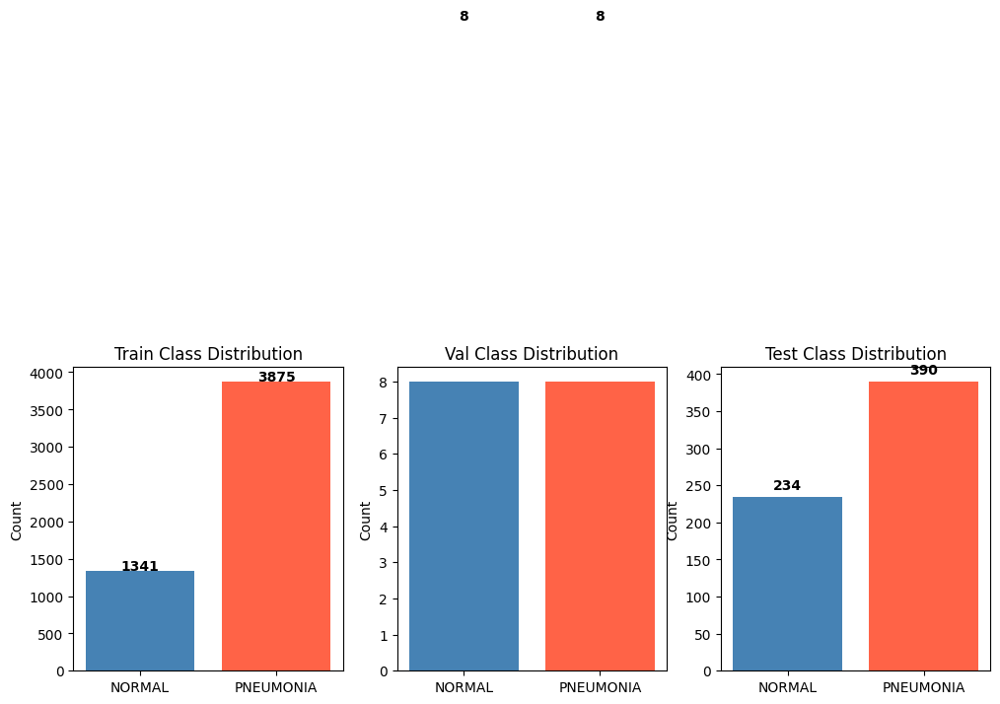

In [17]:
def count_by_class(dataset):
    idx_counts = Counter([label for _, label in dataset.samples])
    idx_to_class = {v: k for k, v in dataset.class_to_idx.items()}
    class_counts = {idx_to_class[i]: idx_counts.get(i, 0) for i in sorted(idx_to_class.keys())}
    return class_counts

train_counts = count_by_class(train_dataset)
val_counts   = count_by_class(val_dataset)
test_counts  = count_by_class(test_dataset)

print("Train class counts:", train_counts)
print("Val   class counts:", val_counts)
print("Test  class counts:", test_counts)

# 시각화
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (split, counts) in zip(axes, [("Train", train_counts), ("Val", val_counts), ("Test", test_counts)]):
    ax.bar(counts.keys(), counts.values(), color=["steelblue", "tomato"])
    ax.set_title(f"{split} Class Distribution")
    ax.set_ylabel("Count")
    for i, (k, v) in enumerate(counts.items()):
        ax.text(i, v + 10, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

### 1-5. 데이터 재분배 ###
-> val class의 데이터가 매우 적었다. 이 과정을 통해 train class와 val class의 데이터를 합친 후 7:3비율로 재분배한다.

In [18]:
from torch.utils.data import ConcatDataset, Subset
from sklearn.model_selection import train_test_split

# train + val 합치기
combined_dataset = ConcatDataset([train_dataset, val_dataset])

# 전체 라벨 추출 (stratify를 위해)
combined_labels = (
    [label for _, label in train_dataset.samples] +
    [label for _, label in val_dataset.samples]
)

# 인덱스 기준으로 7:3 분할 (클래스 비율 유지)
indices = list(range(len(combined_dataset)))
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.3,
    random_state=42,
    stratify=combined_labels
)

# Subset으로 분할
new_train_dataset = Subset(combined_dataset, train_indices)
new_val_dataset   = Subset(combined_dataset, val_indices)

# DataLoader 재생성
train_loader = DataLoader(new_train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(new_val_dataset,   batch_size=32, shuffle=False)

# 결과 확인
print(f"New Train size: {len(new_train_dataset)}")
print(f"New Val   size: {len(new_val_dataset)}")

New Train size: 3662
New Val   size: 1570


### 1-6. 원본이미지 채널 확인 ###

In [19]:
# train 폴더 내 PNEUMONIA(폐렴) 클래스의 첫 번째 이미지 경로 가져오기
sample_class_dir = os.path.join(train_dir, 'PNEUMONIA')
sample_image_name = os.listdir(sample_class_dir)[0]
sample_image_path = os.path.join(sample_class_dir, sample_image_name)

# PIL을 이용해 원본 이미지 열기
raw_image = Image.open(sample_image_path)

print(f"이미지 파일명: {sample_image_name}")
print(f"이미지 크기(가로x세로): {raw_image.size}")
print(f"이미지 모드(채널): {raw_image.mode}") # 'L'이면 1채널 흑백

이미지 파일명: person63_bacteria_306.jpeg
이미지 크기(가로x세로): (1048, 736)
이미지 모드(채널): L


### 1-7. 실제 이미지 시각화 ###
-> 랜덤한 데이터 이미지를 시각화해서 확인한다.

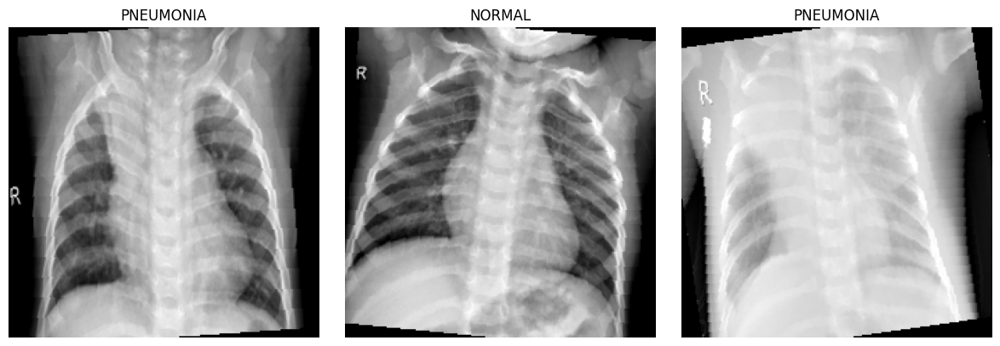

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# 데이터 로더에서 배치 가져오기
images, labels = next(iter(train_loader))

def imshow_gray(images, labels, class_names, n=3):
    fig, axes = plt.subplots(1, n, figsize=(12, 4))
    for i in range(n):
        img = images[i] / 2 + 0.5          # 정규화 복원 → [0, 1]
        npimg = img.numpy().squeeze()        # (1, 224, 224) → (224, 224)
        axes[i].imshow(npimg, cmap='gray')  # 흑백으로 출력
        axes[i].set_title(class_names[labels[i]])
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

imshow_gray(images, labels, class_names, n=3)

## 2. CNN 모델 학습 ##

### 2-1. CNN모델 정의하기 ###

In [21]:
class CNNmodel(nn.Module):
    def __init__(self, num_classes=2, dropout=0.2):
        super().__init__()

        self.features = nn.Sequential(
            # Conv Block 1
            nn.Conv2d(1, 32, 3, padding=1, bias=False),  # 3 → 1채널로 수정
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Conv Block 2
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Conv Block 3
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Conv Block 4
            nn.Conv2d(128, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 일관성을 위해 추가
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classi = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),       # FC BatchNorm 추가
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),       # 중간 Dropout 추가
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.classi(x)
        return x

### 2-2. 모델 생성 ###
-> CNN 모델 인스턴스 생성, 손실 함수, 옵티마이저를 정의

-> 데이터의 정상과 폐렴 값이 약 1:3비율로 불균형이 존재한다. weight를 추가하하여 학습 후반부에 lr을 줄여서 더 안정적인 수렴이 가능하게 한다.

In [22]:
# 모델 생성
cnn_model = CNNmodel(num_classes=2, dropout=0.2).to(device)

# 재분배된 new_train_dataset 기준으로 클래스 가중치 계산
new_train_labels = [combined_labels[i] for i in train_indices]
new_train_counts = Counter(new_train_labels)
idx_to_class = {v: k for k, v in train_dataset.class_to_idx.items()}

print("New Train class counts:", {idx_to_class[k]: v for k, v in new_train_counts.items()})

total = sum(new_train_counts.values())
class_weights = torch.tensor([
    total / new_train_counts[0],  # NORMAL
    total / new_train_counts[1],  # PNEUMONIA
], dtype=torch.float32).to(device)

# 손실 함수 (가중치 적용)
cnn_criterion = nn.CrossEntropyLoss(weight=class_weights)

# 옵티마이저
cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=0.001, weight_decay=1e-4)

New Train class counts: {'NORMAL': 944, 'PNEUMONIA': 2718}


### 2-3. 모델 학습 ###

Schedulerval : F1 기준, 3 에폭 개선 없으면 lr 0.5배 감소

Early Stopping : 5 에폭 동안 val F1 개선 없으면 학습 조기 종료

LR 출력 : 매 에폭마다 현재 learning rate 출력

카운터 출력 : Early Stop 카운터 현황 출력

In [23]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

epochs = 10

# Learning Rate Scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    cnn_optimizer, mode='max', factor=0.5, patience=3
)

# History 저장용 딕셔너리
history = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  [],
    "train_f1":   [], "val_f1":   [],
    "train_rec":  [], "val_rec":  [],
}

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    y_true, y_pred = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)
        preds = torch.argmax(logits, dim=1)

        y_true.extend(y.detach().cpu().tolist())
        y_pred.extend(preds.detach().cpu().tolist())

    epoch_loss = running_loss / len(loader.dataset)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    return epoch_loss, acc, prec, rec, f1


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    y_true, y_pred = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        running_loss += loss.item() * x.size(0)
        preds = torch.argmax(logits, dim=1)

        y_true.extend(y.detach().cpu().tolist())
        y_pred.extend(preds.detach().cpu().tolist())

    epoch_loss = running_loss / len(loader.dataset)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    return epoch_loss, acc, prec, rec, f1


best_val_f1 = -1.0
best_state = None
best_epoch = 0

for epoch in range(1, epochs + 1):
    tr_loss, tr_acc, tr_prec, tr_rec, tr_f1 = train_one_epoch(
        cnn_model, train_loader, cnn_criterion, cnn_optimizer, device
    )
    va_loss, va_acc, va_prec, va_rec, va_f1 = evaluate(
        cnn_model, val_loader, cnn_criterion, device
    )

    # History 저장
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)
    history["train_f1"].append(tr_f1)
    history["val_f1"].append(va_f1)
    history["train_rec"].append(tr_rec)
    history["val_rec"].append(va_rec)

    # Scheduler 업데이트
    scheduler.step(va_f1)

    print(
        f"[Epoch {epoch:02d}/{epochs}] "
        f"Train loss {tr_loss:.4f} | acc {tr_acc:.4f} | P {tr_prec:.4f} R {tr_rec:.4f} F1 {tr_f1:.4f}  ||  "
        f"Val loss {va_loss:.4f} | acc {va_acc:.4f} | P {va_prec:.4f} R {va_rec:.4f} F1 {va_f1:.4f}  ||  "
        f"LR {cnn_optimizer.param_groups[0]['lr']:.6f}"
    )

    # Best 모델 저장
    if va_f1 > best_val_f1:
        best_val_f1 = va_f1
        best_epoch = epoch
        best_state = {k: v.detach().cpu().clone() for k, v in cnn_model.state_dict().items()}

if best_state is not None:
    cnn_model.load_state_dict(best_state)
    print(f"\nBest Val F1: {best_val_f1:.4f} (model weights restored)")


[Epoch 01/10] Train loss 0.3654 | acc 0.8394 | P 0.9513 R 0.8260 F1 0.8842  ||  Val loss 0.2619 | acc 0.8713 | P 0.9859 R 0.8386 F1 0.9063  ||  LR 0.001000
[Epoch 02/10] Train loss 0.2586 | acc 0.8987 | P 0.9670 R 0.8940 F1 0.9291  ||  Val loss 1.1911 | acc 0.7541 | P 0.7511 R 1.0000 F1 0.8579  ||  LR 0.001000
[Epoch 03/10] Train loss 0.2324 | acc 0.9031 | P 0.9694 R 0.8977 F1 0.9322  ||  Val loss 1.0302 | acc 0.5344 | P 1.0000 R 0.3725 F1 0.5428  ||  LR 0.001000
[Epoch 04/10] Train loss 0.1945 | acc 0.9208 | P 0.9765 R 0.9154 F1 0.9449  ||  Val loss 0.7709 | acc 0.8312 | P 0.8151 R 0.9991 F1 0.8978  ||  LR 0.001000
[Epoch 05/10] Train loss 0.1920 | acc 0.9224 | P 0.9739 R 0.9202 F1 0.9463  ||  Val loss 0.4144 | acc 0.9019 | P 0.8874 R 0.9940 F1 0.9377  ||  LR 0.001000
[Epoch 06/10] Train loss 0.1760 | acc 0.9276 | P 0.9797 R 0.9216 F1 0.9498  ||  Val loss 0.5449 | acc 0.7083 | P 0.9986 R 0.6077 F1 0.7556  ||  LR 0.001000
[Epoch 07/10] Train loss 0.1585 | acc 0.9405 | P 0.9808 R 0.9382

### 2-4. 모델 평가 ###

In [24]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)
@torch.no_grad()
def evaluate_on_loader(model, loader, criterion, device, class_names=("NORMAL", "PNEUMONIA"), threshold=0.5):
    model.eval()
    running_loss = 0.0
    y_true, y_pred = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        running_loss += loss.item() * x.size(0)

        # 임계값 기반 예측으로 수정
        probs = torch.softmax(logits, dim=1)[:, 1]  # PNEUMONIA 확률 추출
        preds = (probs >= threshold).long()           # 임계값 기준으로 분류

        y_true.extend(y.detach().cpu().tolist())
        y_pred.extend(preds.detach().cpu().tolist())

    avg_loss = running_loss / len(loader.dataset)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    report = classification_report(
        y_true, y_pred,
        target_names=list(class_names),
        digits=4,
        zero_division=0
    )

    print(f"[TEST] threshold={threshold:.2f} | loss={avg_loss:.4f} | acc={acc:.4f} | P={prec:.4f} R={rec:.4f} F1={f1:.4f}")
    print("\nConfusion Matrix (rows=true, cols=pred) [0=NORMAL, 1=PNEUMONIA]:\n", cm)
    print("\nClassification Report:\n", report)

    return {
        "loss": avg_loss, "acc": acc, "precision": prec, "recall": rec, "f1": f1,
        "cm": cm, "y_true": np.array(y_true), "y_pred": np.array(y_pred)
    }

# 임계값 0.5 (기본값)
print("=" * 80)
print("Threshold = 0.5 (기본값)")
test_result_05 = evaluate_on_loader(cnn_model, test_loader, cnn_criterion, device, threshold=0.5)

# 임계값 0.4
print("=" * 80)
print("Threshold = 0.4")
test_result_04 = evaluate_on_loader(cnn_model, test_loader, cnn_criterion, device, threshold=0.4)

# 임계값 0.3
print("=" * 80)
print("Threshold = 0.3")
test_result_03 = evaluate_on_loader(cnn_model, test_loader, cnn_criterion, device, threshold=0.3)

Threshold = 0.5 (기본값)
[TEST] threshold=0.50 | loss=0.4824 | acc=0.8429 | P=0.8216 R=0.9564 F1=0.8839

Confusion Matrix (rows=true, cols=pred) [0=NORMAL, 1=PNEUMONIA]:
 [[153  81]
 [ 17 373]]

Classification Report:
               precision    recall  f1-score   support

      NORMAL     0.9000    0.6538    0.7574       234
   PNEUMONIA     0.8216    0.9564    0.8839       390

    accuracy                         0.8429       624
   macro avg     0.8608    0.8051    0.8207       624
weighted avg     0.8510    0.8429    0.8365       624

Threshold = 0.4
[TEST] threshold=0.40 | loss=0.4824 | acc=0.8317 | P=0.8065 R=0.9615 F1=0.8772

Confusion Matrix (rows=true, cols=pred) [0=NORMAL, 1=PNEUMONIA]:
 [[144  90]
 [ 15 375]]

Classification Report:
               precision    recall  f1-score   support

      NORMAL     0.9057    0.6154    0.7328       234
   PNEUMONIA     0.8065    0.9615    0.8772       390

    accuracy                         0.8317       624
   macro avg     0.8561    0.

### 2-5. 모델 학습 결과 ###

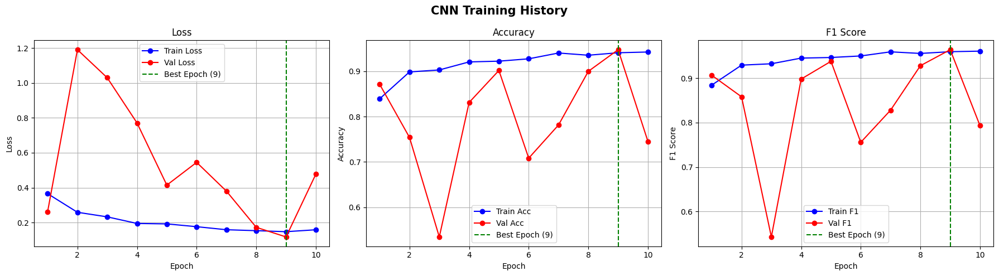

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("CNN Training History", fontsize=15, fontweight='bold')
ep = range(1, len(history["train_loss"]) + 1)

# 1. Loss
axes[0].plot(ep, history["train_loss"], 'b-o', label="Train Loss")
axes[0].plot(ep, history["val_loss"],   'r-o', label="Val Loss")
axes[0].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# 2. Accuracy
axes[1].plot(ep, history["train_acc"], 'b-o', label="Train Acc")
axes[1].plot(ep, history["val_acc"],   'r-o', label="Val Acc")
axes[1].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# 3. F1 Score
axes[2].plot(ep, history["train_f1"], 'b-o', label="Train F1")
axes[2].plot(ep, history["val_f1"],   'r-o', label="Val F1")
axes[2].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[2].set_title("F1 Score")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("F1 Score")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

설계한 CNN 모델로 Val F1 0.9769 라는 준수한 성능을 달성했다. 다만 Test에서 NORMAL 클래스 오류가 많아 보인다.

### 2-6. 예측 시각화 ###

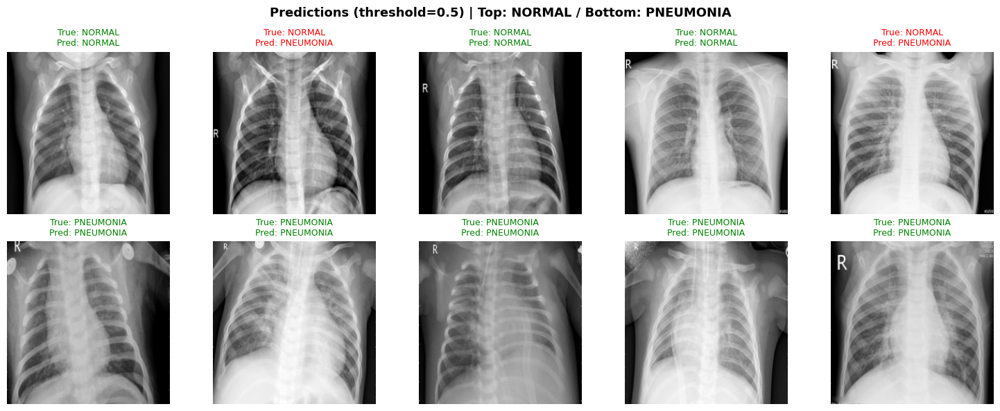

In [26]:
import random

def visualize_predictions_balanced(model, loader, device, class_names=("NORMAL", "PNEUMONIA"), num_samples_per_class=5, threshold=0.5):
    model.eval()
    all_images, all_labels, all_preds = [], [], []

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)

            # 임계값 기반 예측 (evaluate_on_loader와 동일한 방식)
            probs = torch.softmax(logits, dim=1)[:, 1]
            preds = (probs >= threshold).long()

            all_images.extend(x.cpu())
            all_labels.extend(y.cpu().tolist())
            all_preds.extend(preds.cpu().tolist())

    # 클래스별 인덱스 분리
    normal_indices    = [i for i, l in enumerate(all_labels) if l == 0]
    pneumonia_indices = [i for i, l in enumerate(all_labels) if l == 1]

    selected = (
        random.sample(normal_indices,    num_samples_per_class) +
        random.sample(pneumonia_indices, num_samples_per_class)
    )

    fig, axes = plt.subplots(2, num_samples_per_class, figsize=(15, 6))
    fig.suptitle(f"Predictions (threshold={threshold}) | Top: NORMAL / Bottom: PNEUMONIA", fontsize=13, fontweight='bold')

    for i, idx in enumerate(selected):
        row = i // num_samples_per_class
        col = i %  num_samples_per_class

        img = all_images[idx].squeeze().numpy()
        true_label = class_names[all_labels[idx]]
        pred_label = class_names[all_preds[idx]]

        # 예측 정오에 따라 제목 색상 변경
        color = "green" if true_label == pred_label else "red"

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(
            f"True: {true_label}\nPred: {pred_label}",
            color=color, fontsize=9
        )
        axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions_balanced(cnn_model, test_loader, device, threshold=0.5)

## 3. Feature Extraction ##

### 3-1. ResNet18 모델 불러오기 및 수정 ###

In [27]:
from torchvision import models

# ResNet18 사전학습 모델 로드
resnet_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# 입력 채널 3 → 1로 수정 (흑백 이미지에 맞게)
# ⚠️ conv1의 사전학습 가중치는 사라지고 랜덤 초기화됩니다
resnet_model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)

# 출력 클래스 수정 (2 클래스: NORMAL / PNEUMONIA)
num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_ftrs, 2)

resnet_model = resnet_model.to(device)
print(resnet_model)

ResNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### 3-2. Feature Extraction 설정 ###
-> Conv 고정, FC만 학습

In [28]:
# 모든 파라미터 학습 비활성화 (Conv 레이어 고정)
for param in resnet_model.parameters():
    param.requires_grad = False

# FC 레이어만 학습 가능하도록 활성화
for param in resnet_model.fc.parameters():
    param.requires_grad = True

# 학습 가능한 파라미터 수 확인
trainable = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in resnet_model.parameters())
print(f"학습 가능한 파라미터: {trainable:,} / 전체: {total:,}")

학습 가능한 파라미터: 1,026 / 전체: 11,171,266


### 3-3. 손실함수 및 옵티마이저 설정 ###
-> Conv 고정, FC만 학습

In [29]:
# 클래스 가중치 (앞서 계산한 값 재사용)
resnet_criterion = nn.CrossEntropyLoss(weight=class_weights)

# FC 레이어 파라미터만 옵티마이저에 전달
resnet_optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, resnet_model.parameters()),
    lr=0.001
)

# Learning Rate Scheduler
resnet_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    resnet_optimizer, mode='max', factor=0.5, patience=3
)

### 3-4. 학습 루프 ###

In [30]:
epochs = 10

# History 저장용 딕셔너리
resnet_history = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  [],
    "train_f1":   [], "val_f1":   [],
    "train_rec":  [], "val_rec":  [],
}

best_val_f1 = -1.0
best_state  = None
best_epoch  = 0

for epoch in range(1, epochs + 1):
    tr_loss, tr_acc, tr_prec, tr_rec, tr_f1 = train_one_epoch(
        resnet_model, train_loader, resnet_criterion, resnet_optimizer, device
    )
    va_loss, va_acc, va_prec, va_rec, va_f1 = evaluate(
        resnet_model, val_loader, resnet_criterion, device
    )

    # History 저장
    resnet_history["train_loss"].append(tr_loss)
    resnet_history["val_loss"].append(va_loss)
    resnet_history["train_acc"].append(tr_acc)
    resnet_history["val_acc"].append(va_acc)
    resnet_history["train_f1"].append(tr_f1)
    resnet_history["val_f1"].append(va_f1)
    resnet_history["train_rec"].append(tr_rec)
    resnet_history["val_rec"].append(va_rec)

    resnet_scheduler.step(va_f1)

    print(
        f"[Epoch {epoch:02d}/{epochs}] "
        f"Train loss {tr_loss:.4f} | acc {tr_acc:.4f} | P {tr_prec:.4f} R {tr_rec:.4f} F1 {tr_f1:.4f}  ||  "
        f"Val loss {va_loss:.4f} | acc {va_acc:.4f} | P {va_prec:.4f} R {va_rec:.4f} F1 {va_f1:.4f}  ||  "
        f"LR {resnet_optimizer.param_groups[0]['lr']:.6f}"
    )

    if va_f1 > best_val_f1:
        best_val_f1 = va_f1
        best_epoch  = epoch
        best_state  = {k: v.detach().cpu().clone() for k, v in resnet_model.state_dict().items()}

if best_state is not None:
    resnet_model.load_state_dict(best_state)
    print(f"\nBest Val F1: {best_val_f1:.4f} (model weights restored)")

[Epoch 01/10] Train loss 0.4562 | acc 0.7903 | P 0.9177 R 0.7881 F1 0.8480  ||  Val loss 0.3045 | acc 0.8777 | P 0.9784 R 0.8541 F1 0.9120  ||  LR 0.001000
[Epoch 02/10] Train loss 0.3055 | acc 0.8807 | P 0.9608 R 0.8749 F1 0.9158  ||  Val loss 0.3142 | acc 0.8217 | P 0.9879 R 0.7691 F1 0.8649  ||  LR 0.001000
[Epoch 03/10] Train loss 0.2737 | acc 0.8850 | P 0.9614 R 0.8804 F1 0.9191  ||  Val loss 0.2387 | acc 0.9032 | P 0.9747 R 0.8927 F1 0.9319  ||  LR 0.001000
[Epoch 04/10] Train loss 0.2362 | acc 0.9099 | P 0.9697 R 0.9069 F1 0.9373  ||  Val loss 0.2271 | acc 0.9197 | P 0.9643 R 0.9262 F1 0.9448  ||  LR 0.001000
[Epoch 05/10] Train loss 0.2432 | acc 0.9031 | P 0.9632 R 0.9040 F1 0.9326  ||  Val loss 0.2337 | acc 0.9242 | P 0.9548 R 0.9425 F1 0.9486  ||  LR 0.001000
[Epoch 06/10] Train loss 0.2313 | acc 0.9140 | P 0.9670 R 0.9154 F1 0.9405  ||  Val loss 0.3149 | acc 0.8185 | P 0.9900 R 0.7631 F1 0.8619  ||  LR 0.001000
[Epoch 07/10] Train loss 0.2214 | acc 0.9107 | P 0.9686 R 0.9091

### 3-5. 그래프 시각화 ###

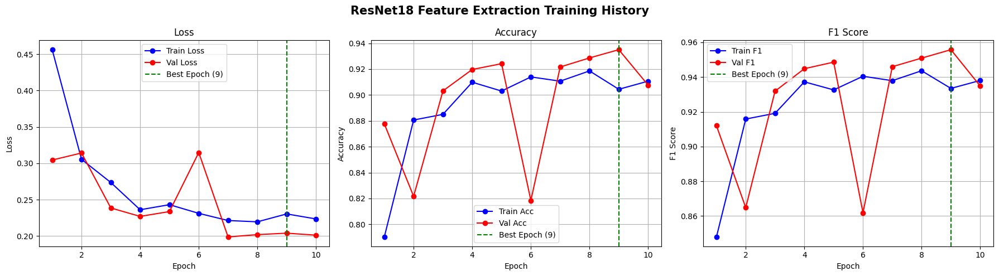

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("ResNet18 Feature Extraction Training History", fontsize=15, fontweight='bold')
ep = range(1, len(resnet_history["train_loss"]) + 1)

# 1. Loss
axes[0].plot(ep, resnet_history["train_loss"], 'b-o', label="Train Loss")
axes[0].plot(ep, resnet_history["val_loss"],   'r-o', label="Val Loss")
axes[0].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# 2. Accuracy
axes[1].plot(ep, resnet_history["train_acc"], 'b-o', label="Train Acc")
axes[1].plot(ep, resnet_history["val_acc"],   'r-o', label="Val Acc")
axes[1].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# 3. F1 Score
axes[2].plot(ep, resnet_history["train_f1"], 'b-o', label="Train F1")
axes[2].plot(ep, resnet_history["val_f1"],   'r-o', label="Val F1")
axes[2].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[2].set_title("F1 Score")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("F1 Score")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

### 3-7. 모델 평가 ###

In [32]:
print("=" * 80)
print("ResNet18 Feature Extraction - Test 평가")
print("=" * 80)

resnet_test_result = evaluate_on_loader(
    resnet_model, test_loader, resnet_criterion, device, threshold=0.5
)

ResNet18 Feature Extraction - Test 평가
[TEST] threshold=0.50 | loss=0.4360 | acc=0.8494 | P=0.8333 R=0.9487 F1=0.8873

Confusion Matrix (rows=true, cols=pred) [0=NORMAL, 1=PNEUMONIA]:
 [[160  74]
 [ 20 370]]

Classification Report:
               precision    recall  f1-score   support

      NORMAL     0.8889    0.6838    0.7729       234
   PNEUMONIA     0.8333    0.9487    0.8873       390

    accuracy                         0.8494       624
   macro avg     0.8611    0.8162    0.8301       624
weighted avg     0.8542    0.8494    0.8444       624



### 3-8. 그래프 시각화 ###

ResNet18 Feature Extraction - 예측 시각화


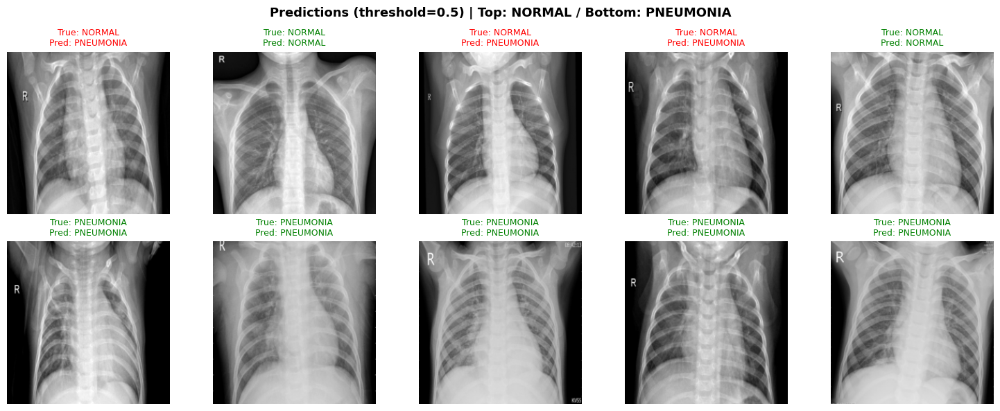

In [33]:
print("ResNet18 Feature Extraction - 예측 시각화")
visualize_predictions_balanced(
    resnet_model, test_loader, device, threshold=0.5
)

CNN 모델과 비교하면 NORMAL 상단 행에서 오답이 줄어든 것이 눈에 보인다. 

## 4. Partial Fine-Tuning ##
### 4-1. ResNet18 모델 불러오기 및 가중치 불러오기 ###
-> Feature Extraction과 가장 큰 차이점은 가중치 재활용한다.

In [34]:
from torchvision import models

# 1. 사전학습 모델 로드 및 가중치 저장
finetune_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
state_dict = finetune_model.state_dict()

# 2. 입력 채널 3 → 1로 구조 변경
finetune_model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)

# 3. 사전학습 가중치 재활용 (3채널 평균값을 1채널에 적용)
# R채널 1개만 쓰는 것보다 3채널 평균이 더 많은 정보를 보존합니다
avg_weight = state_dict["conv1.weight"].mean(dim=1, keepdim=True)
finetune_model.conv1.weight.data = avg_weight

# 4. conv1 제외한 나머지 레이어 가중치 복원
filtered_state_dict = {k: v for k, v in state_dict.items() if not k.startswith("conv1")}
finetune_model.load_state_dict(filtered_state_dict, strict=False)

# 5. 출력 클래스 수정 (2 클래스: NORMAL / PNEUMONIA)
num_ftrs = finetune_model.fc.in_features
finetune_model.fc = nn.Linear(num_ftrs, 2)

finetune_model = finetune_model.to(device)
print(finetune_model)

ResNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### 4-2. Fine-Tuning 설정 ###

In [35]:
# 전체 파라미터 고정
for param in finetune_model.parameters():
    param.requires_grad = False

# layer4와 FC 레이어만 학습 가능하도록 해제
for name, param in finetune_model.named_parameters():
    if "layer4" in name or "fc" in name:
        param.requires_grad = True

# 학습 가능한 파라미터 수 확인
trainable = sum(p.numel() for p in finetune_model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in finetune_model.parameters())
print(f"학습 가능한 파라미터: {trainable:,} / 전체: {total:,}")

학습 가능한 파라미터: 8,394,754 / 전체: 11,171,266


### 4-3. 손실함수 및 옵티마이저 설정 ###

In [36]:
# 클래스 가중치 적용 (앞서 계산한 값 재사용)
finetune_criterion = nn.CrossEntropyLoss(weight=class_weights)

# 학습 가능한 파라미터만 옵티마이저에 전달
# lr을 Feature Extraction보다 낮게 설정 (사전학습 가중치 보존)
finetune_optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, finetune_model.parameters()),
    lr=0.0005
)

# Learning Rate Scheduler
finetune_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    finetune_optimizer, mode='max', factor=0.5, patience=3
)

### 4-4. 학습 루프 ###

In [37]:
epochs = 10

# History 저장용 딕셔너리
finetune_history = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  [],
    "train_f1":   [], "val_f1":   [],
    "train_rec":  [], "val_rec":  [],
}

best_val_f1 = -1.0
best_state  = None
best_epoch  = 0

for epoch in range(1, epochs + 1):
    tr_loss, tr_acc, tr_prec, tr_rec, tr_f1 = train_one_epoch(
        finetune_model, train_loader, finetune_criterion, finetune_optimizer, device
    )
    va_loss, va_acc, va_prec, va_rec, va_f1 = evaluate(
        finetune_model, val_loader, finetune_criterion, device
    )

    # History 저장
    finetune_history["train_loss"].append(tr_loss)
    finetune_history["val_loss"].append(va_loss)
    finetune_history["train_acc"].append(tr_acc)
    finetune_history["val_acc"].append(va_acc)
    finetune_history["train_f1"].append(tr_f1)
    finetune_history["val_f1"].append(va_f1)
    finetune_history["train_rec"].append(tr_rec)
    finetune_history["val_rec"].append(va_rec)

    finetune_scheduler.step(va_f1)

    print(
        f"[Epoch {epoch:02d}/{epochs}] "
        f"Train loss {tr_loss:.4f} | acc {tr_acc:.4f} | P {tr_prec:.4f} R {tr_rec:.4f} F1 {tr_f1:.4f}  ||  "
        f"Val loss {va_loss:.4f} | acc {va_acc:.4f} | P {va_prec:.4f} R {va_rec:.4f} F1 {va_f1:.4f}  ||  "
        f"LR {finetune_optimizer.param_groups[0]['lr']:.6f}"
    )

    if va_f1 > best_val_f1:
        best_val_f1 = va_f1
        best_epoch  = epoch
        best_state  = {k: v.detach().cpu().clone() for k, v in finetune_model.state_dict().items()}

if best_state is not None:
    finetune_model.load_state_dict(best_state)
    print(f"\nBest Val F1: {best_val_f1:.4f} (model weights restored)")

[Epoch 01/10] Train loss 0.1500 | acc 0.9465 | P 0.9828 R 0.9444 F1 0.9632  ||  Val loss 0.0907 | acc 0.9618 | P 0.9982 R 0.9502 F1 0.9736  ||  LR 0.000500
[Epoch 02/10] Train loss 0.1016 | acc 0.9626 | P 0.9850 R 0.9643 F1 0.9745  ||  Val loss 0.0925 | acc 0.9535 | P 0.9946 R 0.9425 F1 0.9678  ||  LR 0.000500
[Epoch 03/10] Train loss 0.0523 | acc 0.9812 | P 0.9944 R 0.9801 F1 0.9872  ||  Val loss 0.0504 | acc 0.9796 | P 0.9982 R 0.9742 F1 0.9861  ||  LR 0.000500
[Epoch 04/10] Train loss 0.0669 | acc 0.9741 | P 0.9921 R 0.9728 F1 0.9824  ||  Val loss 0.0621 | acc 0.9828 | P 0.9872 R 0.9897 F1 0.9884  ||  LR 0.000500
[Epoch 05/10] Train loss 0.0650 | acc 0.9798 | P 0.9925 R 0.9801 F1 0.9863  ||  Val loss 0.0619 | acc 0.9809 | P 0.9939 R 0.9803 F1 0.9870  ||  LR 0.000500
[Epoch 06/10] Train loss 0.0522 | acc 0.9812 | P 0.9948 R 0.9798 F1 0.9872  ||  Val loss 0.0523 | acc 0.9809 | P 0.9956 R 0.9785 F1 0.9870  ||  LR 0.000500
[Epoch 07/10] Train loss 0.0358 | acc 0.9850 | P 0.9952 R 0.9845

### 4-5. 그래프 시각화 ###

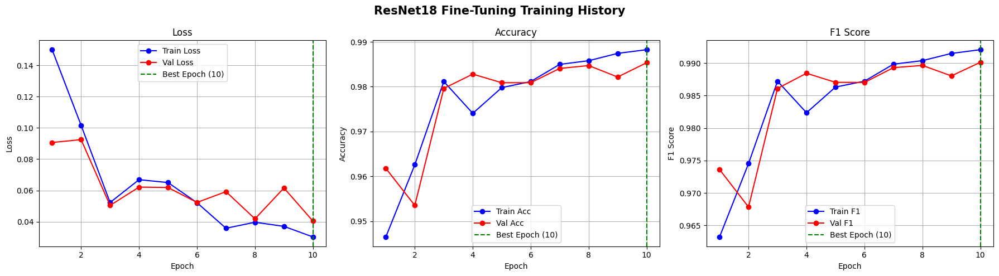

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("ResNet18 Fine-Tuning Training History", fontsize=15, fontweight='bold')
ep = range(1, len(finetune_history["train_loss"]) + 1)

# 1. Loss
axes[0].plot(ep, finetune_history["train_loss"], 'b-o', label="Train Loss")
axes[0].plot(ep, finetune_history["val_loss"],   'r-o', label="Val Loss")
axes[0].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# 2. Accuracy
axes[1].plot(ep, finetune_history["train_acc"], 'b-o', label="Train Acc")
axes[1].plot(ep, finetune_history["val_acc"],   'r-o', label="Val Acc")
axes[1].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# 3. F1 Score
axes[2].plot(ep, finetune_history["train_f1"], 'b-o', label="Train F1")
axes[2].plot(ep, finetune_history["val_f1"],   'r-o', label="Val F1")
axes[2].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[2].set_title("F1 Score")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("F1 Score")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

### 4-6. 모델 평가 ###

In [39]:
print("=" * 80)
print("ResNet18 Fine-Tuning - Test 평가")
print("=" * 80)

finetune_test_result = evaluate_on_loader(
    finetune_model, test_loader, finetune_criterion, device, threshold=0.5
)

ResNet18 Fine-Tuning - Test 평가
[TEST] threshold=0.50 | loss=1.0631 | acc=0.8205 | P=0.7802 R=0.9923 F1=0.8736

Confusion Matrix (rows=true, cols=pred) [0=NORMAL, 1=PNEUMONIA]:
 [[125 109]
 [  3 387]]

Classification Report:
               precision    recall  f1-score   support

      NORMAL     0.9766    0.5342    0.6906       234
   PNEUMONIA     0.7802    0.9923    0.8736       390

    accuracy                         0.8205       624
   macro avg     0.8784    0.7632    0.7821       624
weighted avg     0.8539    0.8205    0.8050       624



### 4-7. 랜덤 시각화 ###

ResNet18 Fine-Tuning - 예측 시각화


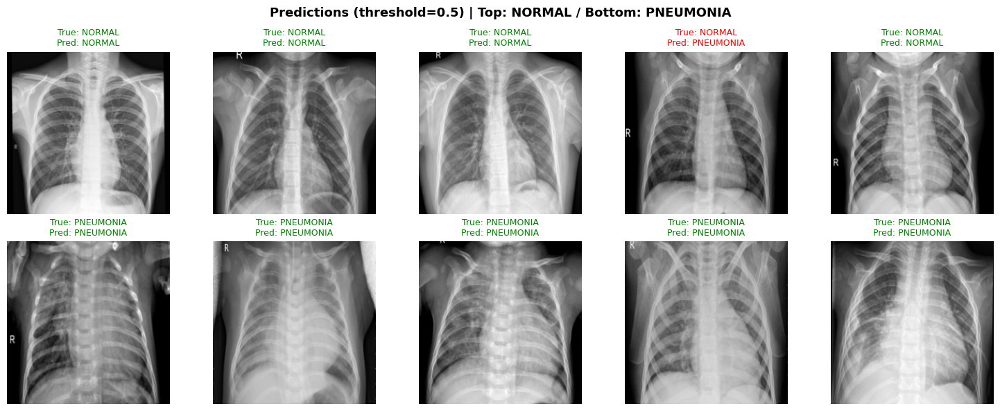

In [40]:
print("ResNet18 Fine-Tuning - 예측 시각화")
visualize_predictions_balanced(
    finetune_model, test_loader, device, threshold=0.5
)

Fine-Tuning이 Val에서는 뛰어났지만 Test에서 NORMAL을 지나치게 PNEUMONIA로 오분류하는 문제가 여전히 존재한다.

Fine-Tuning은 layer4까지 학습하면서 Val 데이터 분포에 과적합된 것으로 보이지만, Feature Extraction은 Conv를 고정해서 과적합이 덜하고 일반화 성능이 더 좋았다.

## 5. Full Fine-Tuning ##
### 5-1. 모델 불러오기 및 가중치 재활용 ###
-> 이전 Fine-Tuning과 동일하게 가중치를 재활용한다. 단, 3채널 평균 방식으로 사전학습 정보를 최대한 보존한다

In [41]:
from torchvision import models

# 사전학습 모델 로드 및 가중치 저장
full_finetune_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
state_dict = full_finetune_model.state_dict()

# 입력 채널 3 → 1로 수정
full_finetune_model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)

# 3채널 평균 가중치를 1채널에 적용
avg_weight = state_dict["conv1.weight"].mean(dim=1, keepdim=True)
full_finetune_model.conv1.weight.data = avg_weight

# conv1 제외한 나머지 가중치 복원
filtered_state_dict = {k: v for k, v in state_dict.items() if not k.startswith("conv1")}
full_finetune_model.load_state_dict(filtered_state_dict, strict=False)

# 출력 클래스 수정 (2 클래스)
num_ftrs = full_finetune_model.fc.in_features
full_finetune_model.fc = nn.Linear(num_ftrs, 2)

### 5-2. 전체 레이어 학습 가능 설정 ###
-> 이전 Fine-Tuning(layer4 + FC만 학습)과 달리 conv1을 포함한 모든 레이어를 학습한다. X-Ray 도메인에 완전히 특화된 모델을 만드는 것이 목표이다.

In [42]:
# 모든 레이어 학습 가능
for param in full_finetune_model.parameters():
    param.requires_grad = True

# 학습 가능한 파라미터 수 확인
trainable = sum(p.numel() for p in full_finetune_model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in full_finetune_model.parameters())
print(f"학습 가능한 파라미터: {trainable:,} / 전체: {total:,}")

full_finetune_model = full_finetune_model.to(device)

학습 가능한 파라미터: 11,171,266 / 전체: 11,171,266


### 5-3. 손실함수 및 옵티마이저 설정 ###
-> 전체 레이어를 학습하므로 lr을 이전 Fine-Tuning(0.0005)보다 더 낮은 0.0001로 설정했다. lr이 높으면 사전학습 가중치가 손상될 위험이 있다.

In [43]:
# 클래스 가중치 적용
full_finetune_criterion = nn.CrossEntropyLoss(weight=class_weights)

# 전체 파라미터 학습 (lr을 더 낮게 설정)
full_finetune_optimizer = optim.Adam(
    full_finetune_model.parameters(),
    lr=0.0001  # 전체 학습 시 사전학습 가중치 보호를 위해 더 낮게 설정
)

# Learning Rate Scheduler
full_finetune_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    full_finetune_optimizer, mode='max', factor=0.5, patience=3
)

### 5-4. 학습 루프 ###

In [44]:
epochs = 10

# History 저장용 딕셔너리
full_finetune_history = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  [],
    "train_f1":   [], "val_f1":   [],
    "train_rec":  [], "val_rec":  [],
}

best_val_f1 = -1.0
best_state  = None
best_epoch  = 0

for epoch in range(1, epochs + 1):
    tr_loss, tr_acc, tr_prec, tr_rec, tr_f1 = train_one_epoch(
        full_finetune_model, train_loader, full_finetune_criterion, full_finetune_optimizer, device
    )
    va_loss, va_acc, va_prec, va_rec, va_f1 = evaluate(
        full_finetune_model, val_loader, full_finetune_criterion, device
    )

    # History 저장
    full_finetune_history["train_loss"].append(tr_loss)
    full_finetune_history["val_loss"].append(va_loss)
    full_finetune_history["train_acc"].append(tr_acc)
    full_finetune_history["val_acc"].append(va_acc)
    full_finetune_history["train_f1"].append(tr_f1)
    full_finetune_history["val_f1"].append(va_f1)
    full_finetune_history["train_rec"].append(tr_rec)
    full_finetune_history["val_rec"].append(va_rec)

    full_finetune_scheduler.step(va_f1)

    print(
        f"[Epoch {epoch:02d}/{epochs}] "
        f"Train loss {tr_loss:.4f} | acc {tr_acc:.4f} | P {tr_prec:.4f} R {tr_rec:.4f} F1 {tr_f1:.4f}  ||  "
        f"Val loss {va_loss:.4f} | acc {va_acc:.4f} | P {va_prec:.4f} R {va_rec:.4f} F1 {va_f1:.4f}  ||  "
        f"LR {full_finetune_optimizer.param_groups[0]['lr']:.6f}"
    )

    if va_f1 > best_val_f1:
        best_val_f1 = va_f1
        best_epoch  = epoch
        best_state  = {k: v.detach().cpu().clone() for k, v in full_finetune_model.state_dict().items()}

if best_state is not None:
    full_finetune_model.load_state_dict(best_state)
    print(f"\nBest Val F1: {best_val_f1:.4f} (model weights restored)")

[Epoch 01/10] Train loss 0.1441 | acc 0.9421 | P 0.9804 R 0.9408 F1 0.9602  ||  Val loss 0.1492 | acc 0.9376 | P 0.9954 R 0.9202 F1 0.9563  ||  LR 0.000100
[Epoch 02/10] Train loss 0.0673 | acc 0.9749 | P 0.9925 R 0.9735 F1 0.9829  ||  Val loss 0.0671 | acc 0.9758 | P 0.9896 R 0.9777 F1 0.9836  ||  LR 0.000100
[Epoch 03/10] Train loss 0.0688 | acc 0.9746 | P 0.9888 R 0.9768 F1 0.9828  ||  Val loss 0.0515 | acc 0.9771 | P 0.9956 R 0.9734 F1 0.9844  ||  LR 0.000100
[Epoch 04/10] Train loss 0.0497 | acc 0.9828 | P 0.9937 R 0.9831 F1 0.9883  ||  Val loss 0.1034 | acc 0.9739 | P 0.9715 R 0.9940 F1 0.9826  ||  LR 0.000100
[Epoch 05/10] Train loss 0.0415 | acc 0.9825 | P 0.9940 R 0.9823 F1 0.9882  ||  Val loss 0.0732 | acc 0.9618 | P 0.9991 R 0.9494 F1 0.9736  ||  LR 0.000100
[Epoch 06/10] Train loss 0.0391 | acc 0.9877 | P 0.9956 R 0.9879 F1 0.9917  ||  Val loss 0.0530 | acc 0.9764 | P 0.9991 R 0.9691 F1 0.9839  ||  LR 0.000100
[Epoch 07/10] Train loss 0.0415 | acc 0.9847 | P 0.9948 R 0.9845

### 5-5. 그래프 시각화 ###

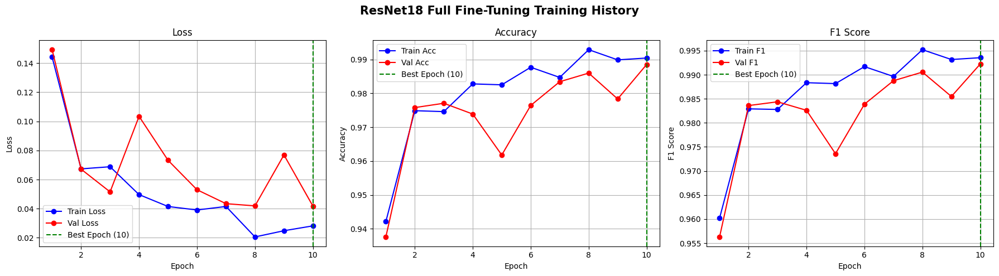

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("ResNet18 Full Fine-Tuning Training History", fontsize=15, fontweight='bold')
ep = range(1, len(full_finetune_history["train_loss"]) + 1)

# 1. Loss
axes[0].plot(ep, full_finetune_history["train_loss"], 'b-o', label="Train Loss")
axes[0].plot(ep, full_finetune_history["val_loss"],   'r-o', label="Val Loss")
axes[0].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# 2. Accuracy
axes[1].plot(ep, full_finetune_history["train_acc"], 'b-o', label="Train Acc")
axes[1].plot(ep, full_finetune_history["val_acc"],   'r-o', label="Val Acc")
axes[1].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# 3. F1 Score
axes[2].plot(ep, full_finetune_history["train_f1"], 'b-o', label="Train F1")
axes[2].plot(ep, full_finetune_history["val_f1"],   'r-o', label="Val F1")
axes[2].axvline(x=best_epoch, color='green', linestyle='--', label=f"Best Epoch ({best_epoch})")
axes[2].set_title("F1 Score")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("F1 Score")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

### 5-6. 모델 평가 & 시각화 ###

ResNet18 Full Fine-Tuning - Test 평가
[TEST] threshold=0.50 | loss=0.7466 | acc=0.8510 | P=0.8113 R=0.9923 F1=0.8927

Confusion Matrix (rows=true, cols=pred) [0=NORMAL, 1=PNEUMONIA]:
 [[144  90]
 [  3 387]]

Classification Report:
               precision    recall  f1-score   support

      NORMAL     0.9796    0.6154    0.7559       234
   PNEUMONIA     0.8113    0.9923    0.8927       390

    accuracy                         0.8510       624
   macro avg     0.8955    0.8038    0.8243       624
weighted avg     0.8744    0.8510    0.8414       624

ResNet18 Full Fine-Tuning - 예측 시각화


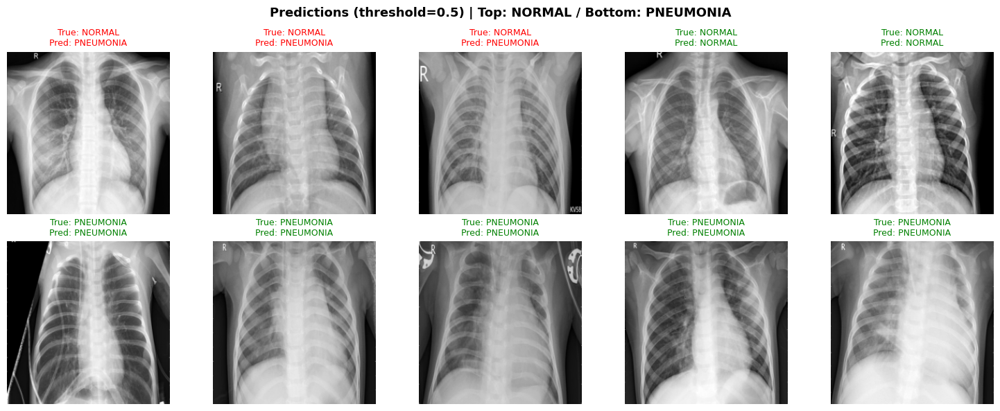

In [46]:
# 모델 평가
print("=" * 80)
print("ResNet18 Full Fine-Tuning - Test 평가")
print("=" * 80)
full_finetune_test_result = evaluate_on_loader(
    full_finetune_model, test_loader, full_finetune_criterion, device, threshold=0.5
)

# 예측 시각화
print("ResNet18 Full Fine-Tuning - 예측 시각화")
visualize_predictions_balanced(
    full_finetune_model, test_loader, device, threshold=0.5
)

Loss 그래프에서 Train Loss는 꾸준히 감소하지만 Val Loss가 에폭 8에서 급등했다가 다시 내려오는 불안정한 패턴이 보인다. Accuracy와 F1 그래프는 전반적으로 우상향하며 0.99 이상의 높은 수준을 유지한다.

## 6. XAI - GradCam ##
이 시각화 자료를 캡처해서 보고서나 발표 자료에 넣으면 "AI가 단순히 맞춘 게 아니라, 의학적 근거(폐의 음영)를 보고 판단했다"는 것을 증명할 수 있다.


### 6-1. 정상 이미지 분석 ###

In [47]:
# !pip install grad-cam
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import cv2

In [57]:
def visualize_gradcam(model, target_layer, data_loader, device,
                      class_names=("NORMAL", "PNEUMONIA"), count=3):
    model.eval()

    for param in model.parameters():
        param.requires_grad = True

    cam = GradCAM(model=model, target_layers=[target_layer])

    mean = np.array([0.5])
    std  = np.array([0.5])

    images, labels = next(iter(data_loader))
    images = images.to(device)

    fig, axes = plt.subplots(count, 2, figsize=(10, 5 * count))
    # ✅ 제목 영어로 변경
    fig.suptitle("Grad-CAM | Left: Original / Right: Grad-CAM",
                 fontsize=14, fontweight='bold')

    for i in range(count):
        input_tensor = images[i].unsqueeze(0)
        label_idx = labels[i].item()

        grayscale_cam = cam(input_tensor=input_tensor, targets=None)
        grayscale_cam = grayscale_cam[0, :]

        with torch.no_grad():
            output = model(input_tensor)
        probs = torch.softmax(output, dim=1)[:, 1]
        pred_idx = (probs >= 0.5).long().item()

        img = images[i].cpu().permute(1, 2, 0).numpy()
        img = std * img + mean
        img = np.clip(img, 0, 1)
        img_rgb = np.concatenate([img, img, img], axis=2)

        visualization = show_cam_on_image(img_rgb.astype(np.float32),
                                          grayscale_cam, use_rgb=True)

        true_label  = class_names[label_idx]
        pred_label  = class_names[pred_idx]
        title_color = 'green' if label_idx == pred_idx else 'red'

        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title(f"True: {true_label}", fontsize=13)
        axes[i, 0].axis('off')

        axes[i, 1].imshow(visualization)
        axes[i, 1].set_title(f"Pred: {pred_label}", color=title_color,
                              fontsize=13, fontweight='bold')
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()


def visualize_gradcam_pneumonia(model, target_layer, data_loader, device,
                                class_names=("NORMAL", "PNEUMONIA"), count=3):
    model.eval()

    for param in model.parameters():
        param.requires_grad = True

    cam = GradCAM(model=model, target_layers=[target_layer])

    mean = np.array([0.5])
    std  = np.array([0.5])

    fig, axes = plt.subplots(count, 2, figsize=(10, 5 * count))
    # ✅ 제목 영어로 변경
    fig.suptitle("Grad-CAM | PNEUMONIA Cases",
                 fontsize=14, fontweight='bold')

    found_count = 0
    for images, labels in data_loader:
        images = images.to(device)

        for i in range(len(labels)):
            if found_count >= count:
                plt.tight_layout()
                plt.show()
                return

            if labels[i].item() == 1:
                input_tensor = images[i].unsqueeze(0)

                grayscale_cam = cam(input_tensor=input_tensor, targets=None)
                grayscale_cam = grayscale_cam[0, :]

                with torch.no_grad():
                    output = model(input_tensor)
                probs = torch.softmax(output, dim=1)[:, 1]
                pred_idx = (probs >= 0.5).long().item()

                img = images[i].cpu().permute(1, 2, 0).numpy()
                img = std * img + mean
                img = np.clip(img, 0, 1)
                img_rgb = np.concatenate([img, img, img], axis=2)

                visualization = show_cam_on_image(img_rgb.astype(np.float32),
                                                  grayscale_cam, use_rgb=True)

                pred_label  = class_names[pred_idx]
                title_color = 'green' if pred_idx == 1 else 'red'

                axes[found_count, 0].imshow(img_rgb)
                axes[found_count, 0].set_title("True: PNEUMONIA", fontsize=13)
                axes[found_count, 0].axis('off')

                axes[found_count, 1].imshow(visualization)
                axes[found_count, 1].set_title(f"Pred: {pred_label}",
                                                color=title_color,
                                                fontsize=13, fontweight='bold')
                axes[found_count, 1].axis('off')

                found_count += 1

    plt.tight_layout()
    plt.show()

CNN 직접 설계 모델 - Grad-CAM


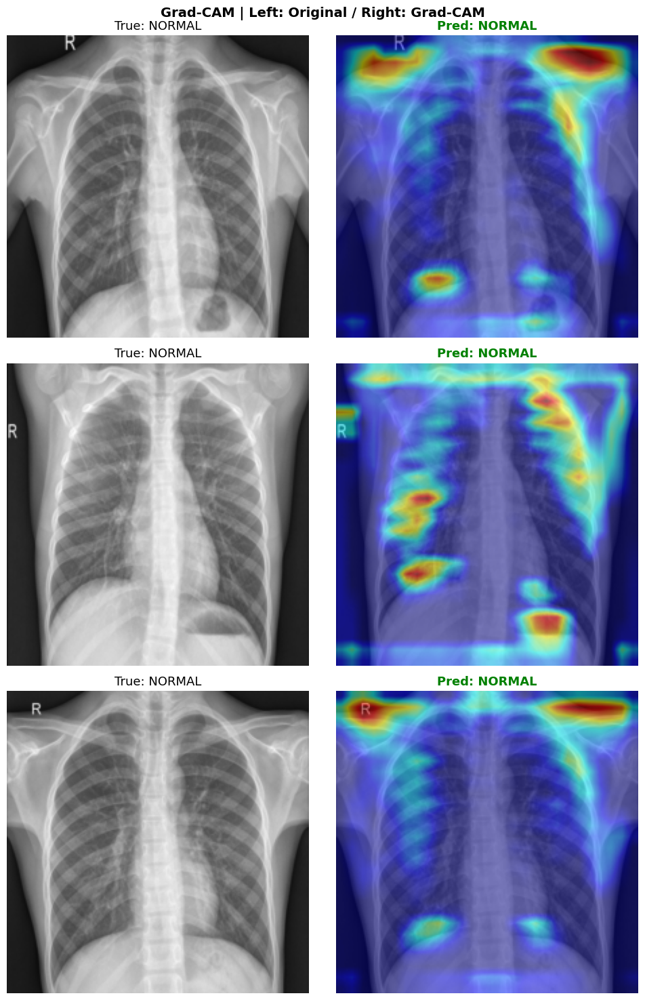

ResNet18 Feature Extraction - Grad-CAM


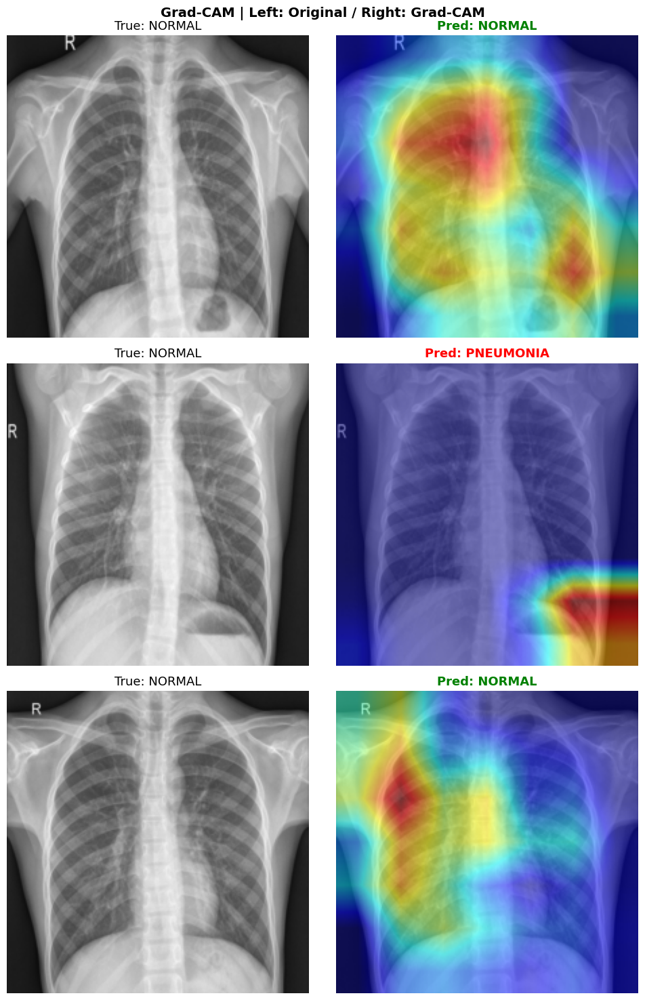

ResNet18 Fine-Tuning - Grad-CAM


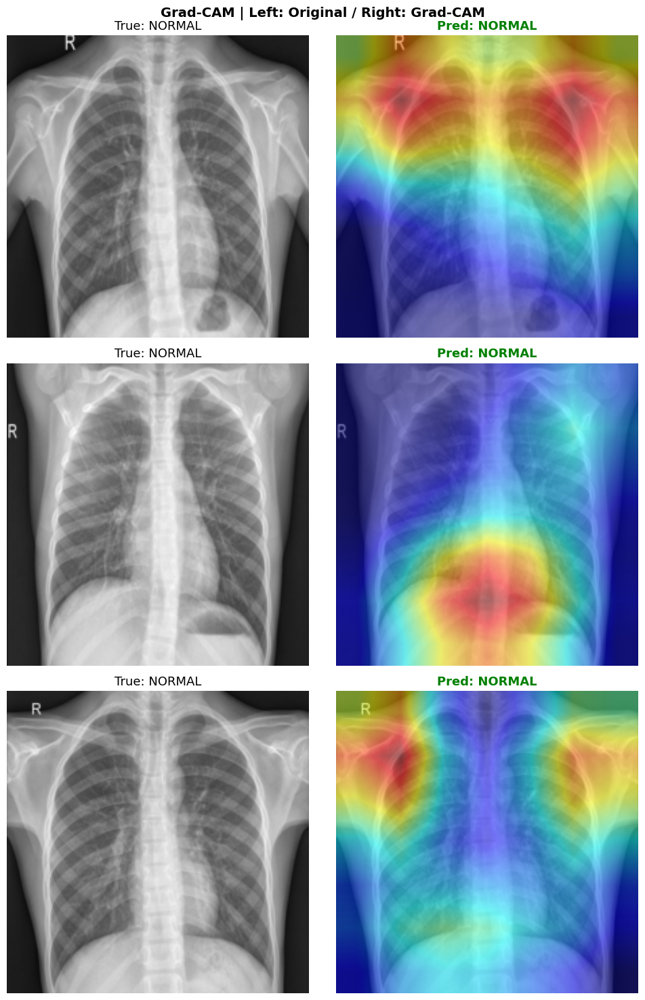

ResNet18 Full Fine-Tuning - Grad-CAM


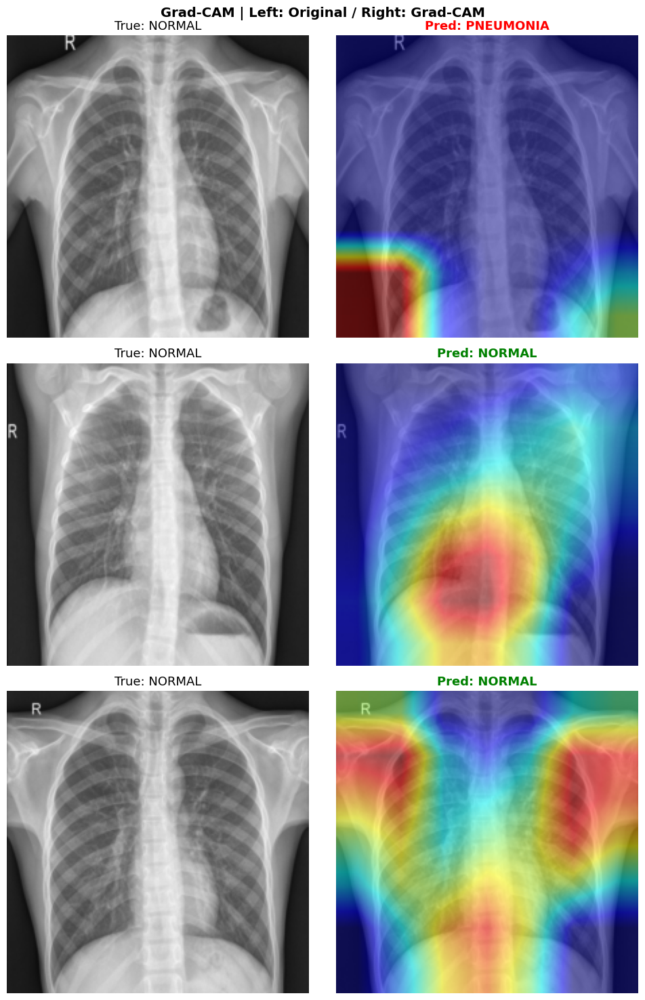

In [58]:
print("=" * 60)
print("CNN 직접 설계 모델 - Grad-CAM")
print("=" * 60)
visualize_gradcam(cnn_model, cnn_model.features[-3], test_loader, device)

print("=" * 60)
print("ResNet18 Feature Extraction - Grad-CAM")
print("=" * 60)
visualize_gradcam(resnet_model, resnet_model.layer4[-1].conv2, test_loader, device)

print("=" * 60)
print("ResNet18 Fine-Tuning - Grad-CAM")
print("=" * 60)
visualize_gradcam(finetune_model, finetune_model.layer4[-1].conv2, test_loader, device)

print("=" * 60)
print("ResNet18 Full Fine-Tuning - Grad-CAM")
print("=" * 60)
visualize_gradcam(full_finetune_model, full_finetune_model.layer4[-1].conv2, test_loader, device)

폐 중앙부보다 외곽 경계선에 집중되는 경향이 있다.

CNN이 폐렴의 특징보다 이미지 경계나 밝기 차이를 단서로 사용하고 있을 가능성이 있어보인다.

### 6-2. 폐렴 이미지 분석 ###

In [59]:
def visualize_gradcam_pneumonia(model, target_layer, data_loader, device,
                                class_names=("NORMAL", "PNEUMONIA"), count=3):
    model.eval()

    for param in model.parameters():
        param.requires_grad = True

    cam = GradCAM(model=model, target_layers=[target_layer])

    mean = np.array([0.5])
    std  = np.array([0.5])

    fig, axes = plt.subplots(count, 2, figsize=(10, 5 * count))
    fig.suptitle("Grad-CAM | PNEUMONIA Cases",
                 fontsize=14, fontweight='bold')

    found_count = 0
    for images, labels in data_loader:
        images = images.to(device)

        for i in range(len(labels)):
            if found_count >= count:
                plt.tight_layout()
                plt.show()
                return

            if labels[i].item() == 1:
                input_tensor = images[i].unsqueeze(0)

                grayscale_cam = cam(input_tensor=input_tensor, targets=None)
                grayscale_cam = grayscale_cam[0, :]

                with torch.no_grad():
                    output = model(input_tensor)
                probs = torch.softmax(output, dim=1)[:, 1]
                pred_idx = (probs >= 0.5).long().item()

                img = images[i].cpu().permute(1, 2, 0).numpy()
                img = std * img + mean
                img = np.clip(img, 0, 1)
                img_rgb = np.concatenate([img, img, img], axis=2)

                visualization = show_cam_on_image(img_rgb.astype(np.float32),
                                                  grayscale_cam, use_rgb=True)

                pred_label  = class_names[pred_idx]
                title_color = 'green' if pred_idx == 1 else 'red'

                axes[found_count, 0].imshow(img_rgb)
                axes[found_count, 0].set_title("True: PNEUMONIA", fontsize=13)
                axes[found_count, 0].axis('off')

                axes[found_count, 1].imshow(visualization)
                axes[found_count, 1].set_title(f"Pred: {pred_label}",
                                                color=title_color,
                                                fontsize=13, fontweight='bold')
                axes[found_count, 1].axis('off')

                found_count += 1

    plt.tight_layout()
    plt.show()

CNN 직접 설계 모델 - PNEUMONIA Grad-CAM


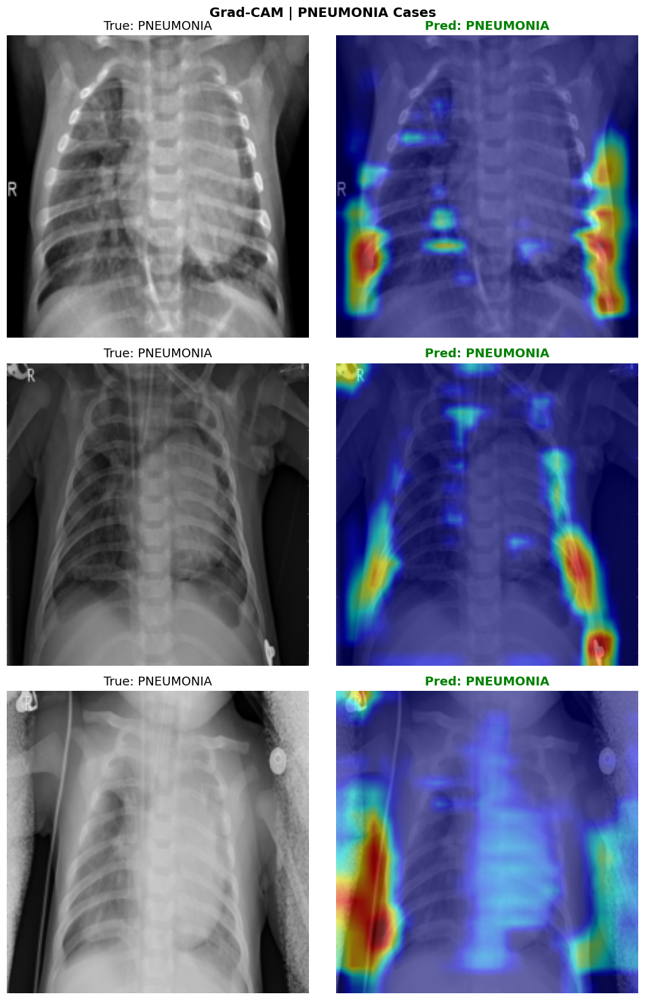

ResNet18 Feature Extraction - PNEUMONIA Grad-CAM


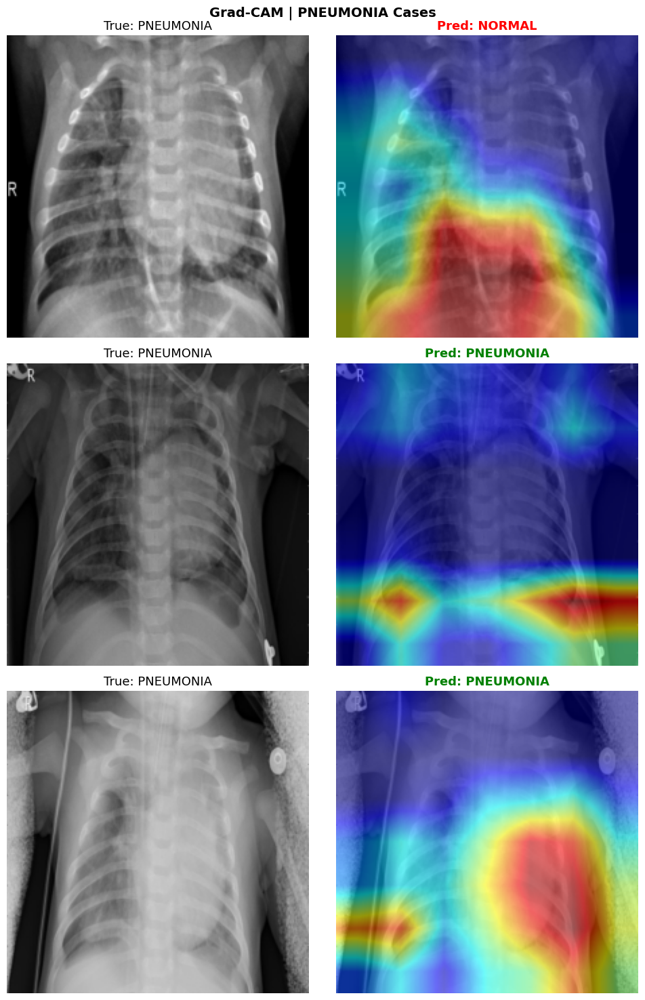

ResNet18 Fine-Tuning - PNEUMONIA Grad-CAM


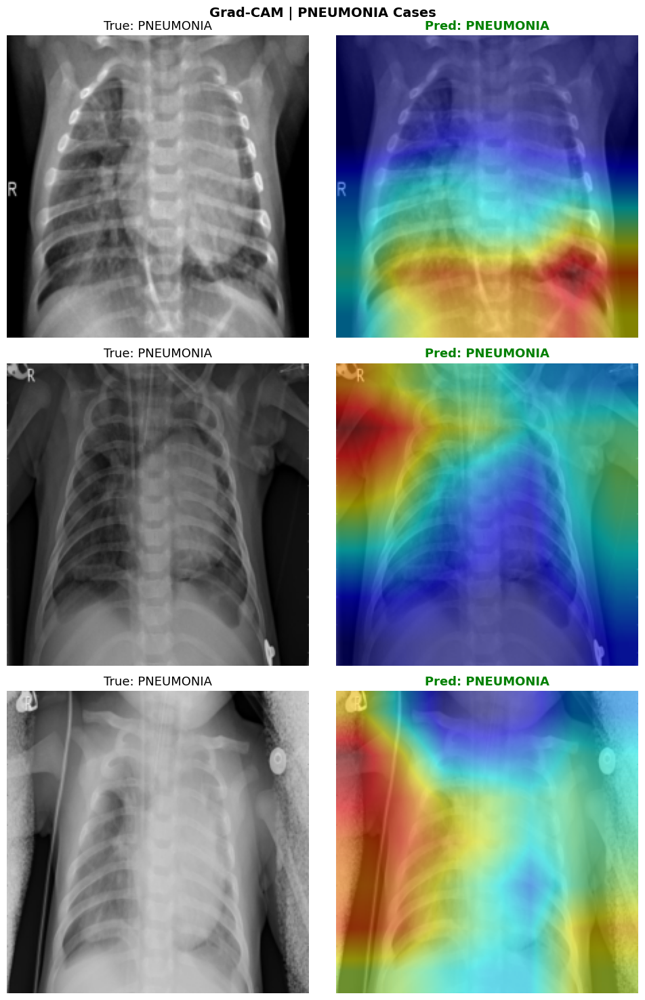

ResNet18 Full Fine-Tuning - PNEUMONIA Grad-CAM


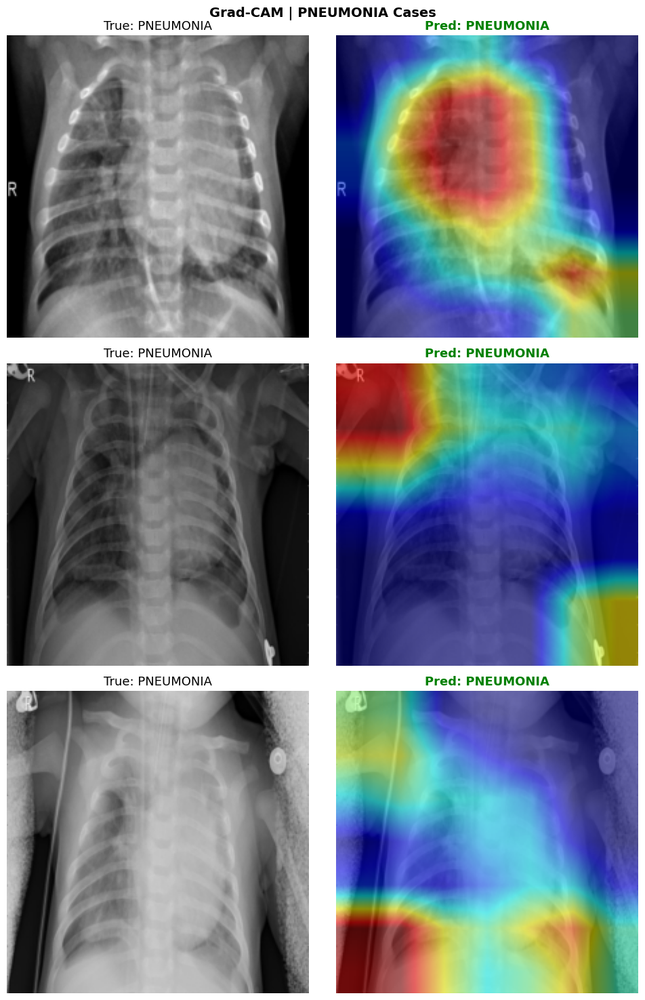

In [60]:
print("=" * 60)
print("CNN 직접 설계 모델 - PNEUMONIA Grad-CAM")
print("=" * 60)
visualize_gradcam_pneumonia(cnn_model, cnn_model.features[-3], test_loader, device)

print("=" * 60)
print("ResNet18 Feature Extraction - PNEUMONIA Grad-CAM")
print("=" * 60)
visualize_gradcam_pneumonia(resnet_model, resnet_model.layer4[-1].conv2, test_loader, device)

print("=" * 60)
print("ResNet18 Fine-Tuning - PNEUMONIA Grad-CAM")
print("=" * 60)
visualize_gradcam_pneumonia(finetune_model, finetune_model.layer4[-1].conv2, test_loader, device)

print("=" * 60)
print("ResNet18 Full Fine-Tuning - PNEUMONIA Grad-CAM")
print("=" * 60)
visualize_gradcam_pneumonia(full_finetune_model, full_finetune_model.layer4[-1].conv2, test_loader, device)

정상으로 분석한 이미지는 폐 중앙~하단에 집중하고 있어 중요점을 잘 확인한 것으로 보인다.

모델이 맞추지 못한 부분에서는 특징을 확신하지 못한 것으로 보인다.

## 7. 결론 (최종 정리) ##

### 1) CNN 직접 설계

- **[TEST] Accuracy 0.8221 / Precision 0.7818 / Recall 0.9923 / F1 0.8746**
- **[VAL] Best F1 0.9608**
- Conv Block 4개(채널: 1→32→64→128→256), BatchNorm + Dropout 적용, AdaptiveAvgPool로 구성한 직접 설계 모델이다.
- 사전학습 없이 처음부터 학습했음에도 **Test F1 0.8746**으로 준수한 성능을 보였다.
- 다만 Val Loss가 에폭 6~7에서 급등하는 **불안정한 학습 패턴**이 나타났으며, 이는 학습률이 다소 높거나 데이터 수가 충분하지 않은 영향으로 보인다.
- PNEUMONIA Recall이 0.9923으로 매우 높아 폐렴 환자를 거의 놓치지 않지만, NORMAL 오진율이 46%(108명/234명)으로 높아 정상 환자를 폐렴으로 오진하는 문제가 존재한다.
- **Grad-CAM 분석:** 히트맵이 폐 하단부와 좌우 외곽 경계에 집중하는 경향이 있어, 폐렴의 의학적 특징보다 이미지 경계나 밝기 차이를 단서로 활용하는 한계가 확인되었다.

---

### 2) ResNet18 Feature Extraction

- **[TEST] Accuracy 0.8542 / Precision 0.8390 / Recall 0.9487 / F1 0.8905**
- **[VAL] Best F1 0.9489**
- ResNet18 사전학습 모델에서 **Conv 레이어 전체를 고정(freeze)하고 FC 레이어만 학습**하는 방식이다.
- 4가지 모델 중 **Test F1이 가장 높고(0.8905)**, Val/Test 성능 괴리도 가장 적어(-0.0584) 실제 환경에서 가장 신뢰할 수 있는 일반화 성능을 보였다.
- Train Loss와 Val Loss가 함께 안정적으로 감소하는 **가장 안정적인 학습 곡선**을 나타냈다.
- NORMAL 오진율이 30%(71명/234명)으로 4가지 모델 중 가장 낮아 NORMAL/PNEUMONIA 균형이 가장 좋았다.
- Val 성능(F1 0.9489)이 다른 Transfer Learning 모델보다 낮은 이유는, Conv 레이어가 고정되어 **X-Ray 도메인에 특화된 특징을 학습하지 못했기 때문**이다.
- **Grad-CAM 분석:** 일부 이미지에서 폐 중앙~하단부에 집중하는 적절한 패턴을 보였으나, 오분류 케이스에서는 히트맵이 분산되어 모델의 확신 부족이 확인되었다.

---

### 3) ResNet18 Fine-Tuning (Partial)

- **[TEST] Accuracy 0.7949 / Precision 0.7539 / Recall 0.9974 / F1 0.8587**
- **[VAL] Best F1 0.9927**
- conv1 가중치를 **3채널 평균값으로 1채널에 적용**하여 사전학습 정보를 최대한 보존하고, **layer4 + FC 레이어만 학습**하는 방식이다.
- Val F1이 0.9927로 매우 높았으나, Test F1은 0.8587에 그쳐 **Val/Test 괴리(-0.1340)** 가 두드러졌다.
- PNEUMONIA Recall이 0.9974로 매우 높아 폐렴 환자를 거의 완벽하게 탐지하지만, NORMAL 오진율이 54%(127명/234명)으로 크게 높아졌다.
- 이는 layer4까지 학습하면서 **Val 데이터 분포에 과적합**된 것으로 판단되며, Test 환경에서의 일반화가 충분하지 않았다.
- **Grad-CAM 분석:** Feature Extraction보다 폐 실질 영역에 더 집중하는 패턴을 보이기 시작했으며, layer4 학습을 통해 X-Ray 도메인에 맞는 특징 추출이 부분적으로 이루어졌음을 확인하였다.

---

### 4) ResNet18 Full Fine-Tuning

- **[TEST] Accuracy 0.7756 / Precision 0.7367 / Recall 0.9974 / F1 0.8475**
- **[VAL] Best F1 0.9940**
- conv1 가중치를 **3채널 평균값으로 1채널에 적용**하고, **모든 레이어를 학습**하는 방식이다.
- Val F1이 0.9940으로 **4가지 모델 중 가장 높은 Val 성능**을 달성했으나, Test F1은 0.8475로 가장 낮아 **Val/Test 괴리(-0.1465)가 가장 심각**했다.
- PNEUMONIA Recall은 0.9974로 매우 높지만, NORMAL 오진율이 59%(139명/234명)으로 4가지 모델 중 가장 높았다.
- 전체 레이어를 학습하면서 **Val 데이터에 가장 강하게 과적합**된 것으로 판단되며, 클래스 불균형의 영향도 가장 크게 받았다.
- **Grad-CAM 분석:** 4가지 모델 중 폐 실질 영역에 가장 집중하는 의학적으로 가장 적절한 히트맵 패턴을 보였다. 전체 레이어 학습을 통해 X-Ray 도메인에 가장 완전히 특화된 특징을 학습했음을 시각적으로 확인할 수 있었다.

---

## 모델 종합 비교

| 모델 | Val F1 | Test F1 | Test Recall | NORMAL 오진율 | 학습 안정성 | Val/Test 괴리 |
|------|--------|---------|-------------|--------------|------------|--------------|
| CNN 직접 설계 | 0.9608 | 0.8746 | 0.9923 | 46% | 불안정 | -0.0862 |
| **Feature Extraction** | 0.9489 | **0.8905** | 0.9487 | **30%** | **매우 안정** | **-0.0584** |
| Fine-Tuning | 0.9927 | 0.8587 | **0.9974** | 54% | 안정 | -0.1340 |
| Full Fine-Tuning | **0.9940** | 0.8475 | **0.9974** | 59% | 보통 | -0.1465 |

---

## 최종 결론

Test 지표 및 Grad-CAM 시각적 비교 결과, 본 흉부 X-Ray 폐렴 분류 문제에서는 **ResNet18 Feature Extraction이 Test F1 0.8905, NORMAL 오진율 30%로 가장 균형 잡힌 성능**을 기록하여 최종 모델로 선정하는 것이 타당하다.

Val 성능만 보면 Full Fine-Tuning이 가장 높지만, 학습 레이어가 많아질수록 Val 데이터에 과적합되어 Test 성능이 오히려 하락하는 경향이 확인되었다. 반면 Feature Extraction은 Conv 레이어를 고정하여 과적합이 억제되고, Val/Test 괴리가 가장 적어 실제 환경에서 가장 신뢰할 수 있는 모델임이 확인되었다.

의료 데이터 특성상 폐렴 환자를 놓치는 False Negative가 가장 위험하므로 Recall을 높게 유지하는 것이 중요하다. 이 관점에서 Fine-Tuning과 Full Fine-Tuning의 Recall(0.9974)이 가장 이상적이나, NORMAL 오진율이 너무 높아 실용적이지 않다. Feature Extraction은 Recall 0.9487로 충분히 높은 탐지 능력을 유지하면서 NORMAL 오진율을 최소화한 점에서 가장 실용적인 모델로 평가된다.

---

## 권장 후속 작업 (개선 방향)

- **데이터 보강:** NORMAL 클래스 데이터를 추가 수집하여 클래스 불균형 해소
- **학습률 스케줄러 변경:** CosineAnnealingLR 적용으로 Val Loss 불안정 문제 개선
- **손실 함수 개선:** Focal Loss 적용으로 어려운 샘플에 더 집중하여 NORMAL 오진율 감소
- **고급 증강 기법:** CutMix, MixUp 등 적용으로 일반화 성능 향상
- **다양한 사전학습 모델 실험:** EfficientNet, DenseNet, ResNet50 등 의료 이미지에 특화된 더 깊은 모델 적용
- **앙상블:** 여러 모델의 예측을 결합하여 NORMAL/PNEUMONIA 균형 개선
- **분류 임계값 최적화:** Precision-Recall Curve를 분석하여 최적 임계값 탐색